In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [4]:
# Core experiment settings
N_TRAIN = 150
N_TEST = 1000
D_MAX = 400
NOISE_STD = 0.5

# Model dimensions to test
D_VALUES = np.array([
    10, 20, 40, 60, 80, 100, 120, 130, 140,
    145, 148, 149, 150, 151, 152, 155, 160,
    170, 180, 200, 250, 300, 350, 400
])

print(f"Training samples: {N_TRAIN}")
print(f"Test samples: {N_TEST}")
print(f"Interpolation threshold: d = {N_TRAIN}")

Training samples: 150
Test samples: 1000
Interpolation threshold: d = 150


In [5]:
# Generate the full synthetic regression problem

# Feature matrices
X_train_full = rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TRAIN, D_MAX)
)

X_test_full = rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TEST, D_MAX)
)

# True coefficient vector
beta_true = rng.normal(size=D_MAX)

# Normalize beta so that the overall signal strength is controlled
beta_true = beta_true / np.linalg.norm(beta_true)

# Gaussian noise
train_noise = rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TRAIN
)

test_noise = rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TEST
)

# Generate labels: y = X beta + epsilon
y_train = X_train_full @ beta_true + train_noise
y_test = X_test_full @ beta_true + test_noise

print("X_train shape:", X_train_full.shape)
print("X_test shape:", X_test_full.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("||beta_true||:", np.linalg.norm(beta_true))

X_train shape: (150, 400)
X_test shape: (1000, 400)
y_train shape: (150,)
y_test shape: (1000,)
||beta_true||: 1.0


In [6]:
# Generate a reproducible synthetic regression dataset

data_rng = np.random.default_rng(RANDOM_SEED)

# Feature matrices
X_train_full = data_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TRAIN, D_MAX)
)

X_test_full = data_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TEST, D_MAX)
)

# True coefficients:
# earlier features carry more signal than later ones
feature_index = np.arange(D_MAX)

signs = data_rng.choice([-1.0, 1.0], size=D_MAX)

beta_true = signs * np.exp(-0.02 * feature_index)

# Normalize total signal strength
beta_true = beta_true / np.linalg.norm(beta_true)

# Add Gaussian noise
train_noise = data_rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TRAIN
)

test_noise = data_rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TEST
)

# Labels: y = X beta + noise
y_train = X_train_full @ beta_true + train_noise
y_test = X_test_full @ beta_true + test_noise

print("X_train shape:", X_train_full.shape)
print("X_test shape:", X_test_full.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("beta norm:", np.linalg.norm(beta_true))

X_train shape: (150, 400)
X_test shape: (1000, 400)
y_train shape: (150,)
y_test shape: (1000,)
beta norm: 0.9999999999999999


In [7]:
def fit_min_norm_least_squares(X, y, tol=1e-10):
    """
    Fit linear regression using the minimum-norm least squares solution.

    Works both when:
    - d < n  : ordinary least squares
    - d >= n : minimum-norm interpolating solution
    """

    # Singular Value Decomposition
    U, singular_values, Vt = np.linalg.svd(
        X,
        full_matrices=False
    )

    # Avoid dividing by singular values that are numerically zero
    cutoff = tol * singular_values[0]

    inverse_singular_values = np.where(
        singular_values > cutoff,
        1.0 / singular_values,
        0.0
    )

    # Moore-Penrose solution
    w = Vt.T @ (
        inverse_singular_values * (U.T @ y)
    )

    return w


def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [8]:
# Quick test in the underparameterized regime

d = 40

X_train = X_train_full[:, :d]
X_test = X_test_full[:, :d]

w_hat = fit_min_norm_least_squares(
    X_train,
    y_train
)

train_predictions = X_train @ w_hat
test_predictions = X_test @ w_hat

train_mse = mean_squared_error(
    y_train,
    train_predictions
)

test_mse = mean_squared_error(
    y_test,
    test_predictions
)

print("d =", d)
print("w shape:", w_hat.shape)
print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

d = 40
w shape: (40,)
Train MSE: 0.3688858806787832
Test MSE: 0.5893246800404917


In [9]:
train_errors = []
test_errors = []

for d in D_VALUES:

    # Use only the first d features
    X_train = X_train_full[:, :d]
    X_test = X_test_full[:, :d]

    # Fit minimum-norm least squares
    w_hat = fit_min_norm_least_squares(
        X_train,
        y_train
    )

    # Predictions
    train_predictions = X_train @ w_hat
    test_predictions = X_test @ w_hat

    # Errors
    train_mse = mean_squared_error(
        y_train,
        train_predictions
    )

    test_mse = mean_squared_error(
        y_test,
        test_predictions
    )

    train_errors.append(train_mse)
    test_errors.append(test_mse)

print("Experiment completed.")
print("Number of dimensions tested:", len(D_VALUES))

Experiment completed.
Number of dimensions tested: 24


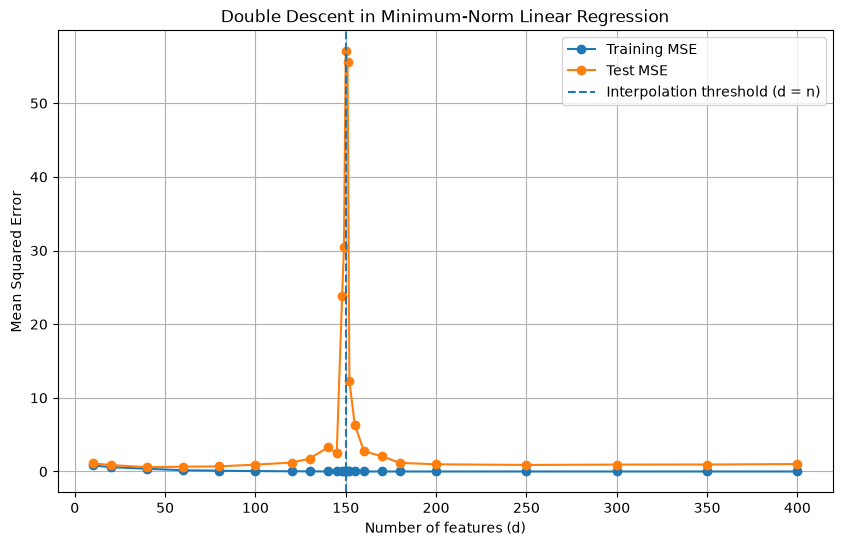

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES,
    train_errors,
    marker="o",
    label="Training MSE"
)

plt.plot(
    D_VALUES,
    test_errors,
    marker="o",
    label="Test MSE"
)

plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Double Descent in Minimum-Norm Linear Regression")

plt.legend()
plt.grid(True)

plt.show()

In [11]:
def run_synthetic_experiment(seed):
    """
    Run one complete synthetic double-descent experiment.
    Returns train and test MSE for every value of d.
    """

    local_rng = np.random.default_rng(seed)

    # Generate features
    X_train = local_rng.normal(
        size=(N_TRAIN, D_MAX)
    )

    X_test = local_rng.normal(
        size=(N_TEST, D_MAX)
    )

    # Generate true coefficients
    feature_index = np.arange(D_MAX)

    signs = local_rng.choice(
        [-1.0, 1.0],
        size=D_MAX
    )

    beta = signs * np.exp(
        -0.02 * feature_index
    )

    beta = beta / np.linalg.norm(beta)

    # Generate noisy labels
    y_train_local = (
        X_train @ beta
        + local_rng.normal(
            scale=NOISE_STD,
            size=N_TRAIN
        )
    )

    y_test_local = (
        X_test @ beta
        + local_rng.normal(
            scale=NOISE_STD,
            size=N_TEST
        )
    )

    train_errors_local = []
    test_errors_local = []

    for d in D_VALUES:

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        w_hat = fit_min_norm_least_squares(
            Xtr,
            y_train_local
        )

        train_pred = Xtr @ w_hat
        test_pred = Xte @ w_hat

        train_errors_local.append(
            mean_squared_error(
                y_train_local,
                train_pred
            )
        )

        test_errors_local.append(
            mean_squared_error(
                y_test_local,
                test_pred
            )
        )

    return (
        np.array(train_errors_local),
        np.array(test_errors_local)
    )

In [12]:
N_REPETITIONS = 30

all_train_errors = []
all_test_errors = []

for seed in range(N_REPETITIONS):

    train_err, test_err = run_synthetic_experiment(seed)

    all_train_errors.append(train_err)
    all_test_errors.append(test_err)

all_train_errors = np.array(all_train_errors)
all_test_errors = np.array(all_test_errors)

mean_train_errors = all_train_errors.mean(axis=0)
mean_test_errors = all_test_errors.mean(axis=0)

std_train_errors = all_train_errors.std(axis=0)
std_test_errors = all_test_errors.std(axis=0)

print("Shape train errors:", all_train_errors.shape)
print("Shape test errors:", all_test_errors.shape)
print("Experiment repeated", N_REPETITIONS, "times.")

Shape train errors: (30, 24)
Shape test errors: (30, 24)
Experiment repeated 30 times.


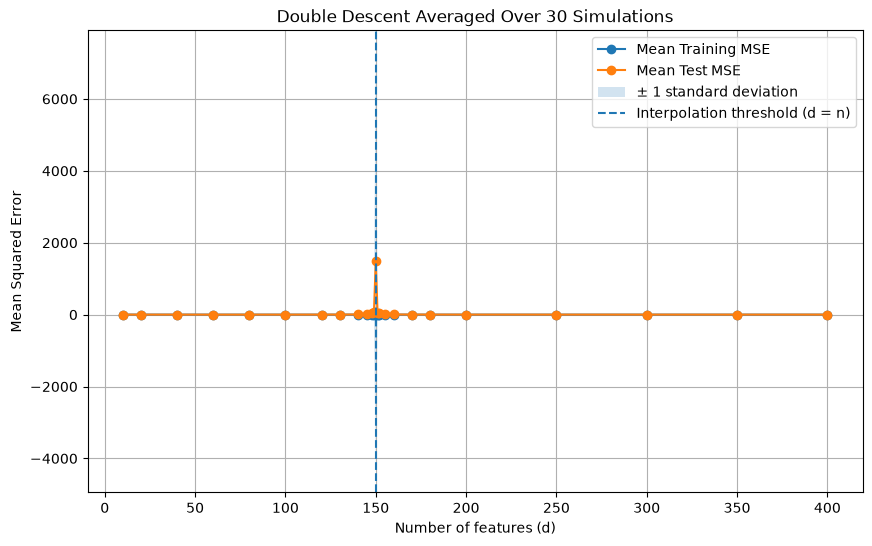

In [ ]:
plt.figure(figsize=(10, 4))

# Mean training error
plt.plot(
    D_VALUES,
    mean_train_errors,
    marker="o",
    label="Mean Training MSE"
)

# Mean test error
plt.plot(
    D_VALUES,
    mean_test_errors,
    marker="o",
    label="Mean Test MSE"
)

# Variability across repetitions
plt.fill_between(
    D_VALUES,
    mean_test_errors - std_test_errors,
    mean_test_errors + std_test_errors,
    alpha=0.2,
    label="± 1 standard deviation"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title(
    f"Double Descent Averaged Over {N_REPETITIONS} Simulations"
)

plt.legend()
plt.grid(True)

plt.show()

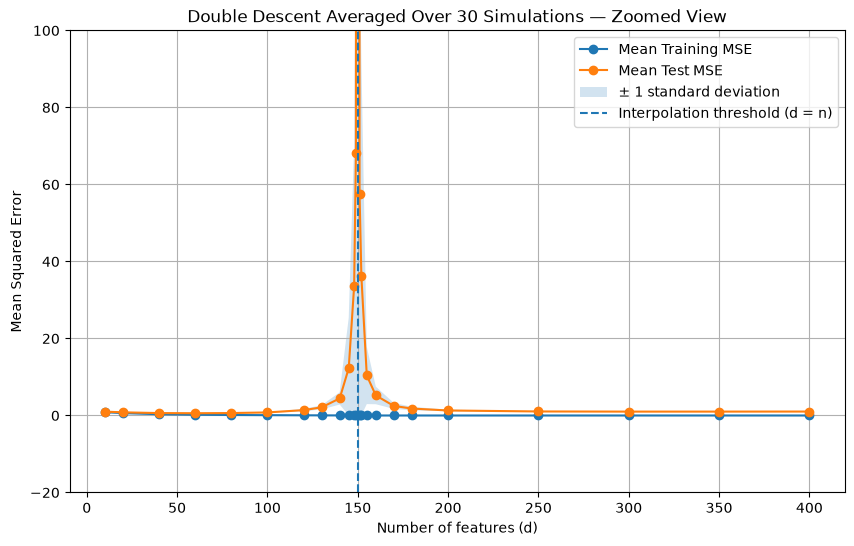

In [18]:
plt.figure(figsize=(10, 6))

# Mean training error
plt.plot(
    D_VALUES,
    mean_train_errors,
    marker="o",
    label="Mean Training MSE"
)

# Mean test error
plt.plot(
    D_VALUES,
    mean_test_errors,
    marker="o",
    label="Mean Test MSE"
)

# Standard deviation band
lower_bound = np.maximum(
    mean_test_errors - std_test_errors,
    0
)

upper_bound = mean_test_errors + std_test_errors

plt.fill_between(
    D_VALUES,
    lower_bound,
    upper_bound,
    alpha=0.2,
    label="± 1 standard deviation"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title(
    f"Double Descent Averaged Over {N_REPETITIONS} Simulations — Zoomed View"
)

# Zoom on the informative part of the curve
plt.ylim(-20, 100)

plt.legend()
plt.grid(True)

plt.show()

In [19]:
def fit_ridge_regression(X, y, alpha):
    """
    Fit Ridge Regression from scratch.

    Parameters
    ----------
    X : array of shape (n_samples, n_features)
    y : array of shape (n_samples,)
    alpha : regularization strength

    Returns
    -------
    w : estimated coefficient vector
    """

    d = X.shape[1]

    # X^T X + alpha I
    regularized_matrix = (
        X.T @ X
        + alpha * np.eye(d)
    )

    # X^T y
    right_hand_side = X.T @ y

    # Solve the linear system
    w = np.linalg.solve(
        regularized_matrix,
        right_hand_side
    )

    return w

In [20]:
RIDGE_ALPHA = 1.0

ridge_train_errors = []
ridge_test_errors = []

for d in D_VALUES:

    # Use the same features as in the least-squares experiment
    X_train = X_train_full[:, :d]
    X_test = X_test_full[:, :d]

    # Fit Ridge Regression
    w_ridge = fit_ridge_regression(
        X_train,
        y_train,
        alpha=RIDGE_ALPHA
    )

    # Predictions
    train_predictions = X_train @ w_ridge
    test_predictions = X_test @ w_ridge

    # Errors
    ridge_train_errors.append(
        mean_squared_error(
            y_train,
            train_predictions
        )
    )

    ridge_test_errors.append(
        mean_squared_error(
            y_test,
            test_predictions
        )
    )

ridge_train_errors = np.array(ridge_train_errors)
ridge_test_errors = np.array(ridge_test_errors)

print("Ridge experiment completed.")
print("Alpha:", RIDGE_ALPHA)

Ridge experiment completed.
Alpha: 1.0


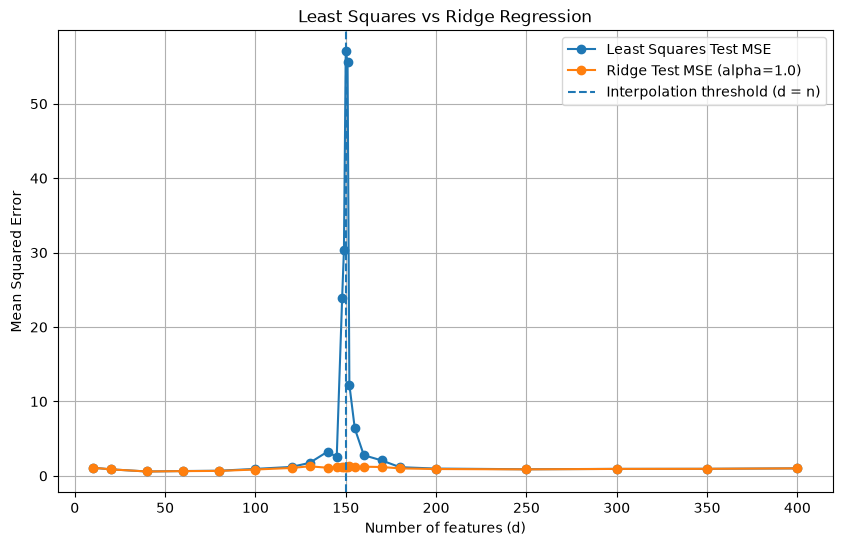

In [21]:
plt.figure(figsize=(10, 6))

# Least Squares
plt.plot(
    D_VALUES,
    test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

# Ridge
plt.plot(
    D_VALUES,
    ridge_test_errors,
    marker="o",
    label=f"Ridge Test MSE (alpha={RIDGE_ALPHA})"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Least Squares vs Ridge Regression")

plt.legend()
plt.grid(True)

plt.show()

In [22]:
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0]

ridge_results = {}

for alpha in RIDGE_ALPHAS:

    test_errors_alpha = []

    for d in D_VALUES:

        X_train = X_train_full[:, :d]
        X_test = X_test_full[:, :d]

        w_ridge = fit_ridge_regression(
            X_train,
            y_train,
            alpha=alpha
        )

        test_predictions = X_test @ w_ridge

        test_errors_alpha.append(
            mean_squared_error(
                y_test,
                test_predictions
            )
        )

    ridge_results[alpha] = np.array(test_errors_alpha)

print("Ridge sensitivity analysis completed.")

Ridge sensitivity analysis completed.


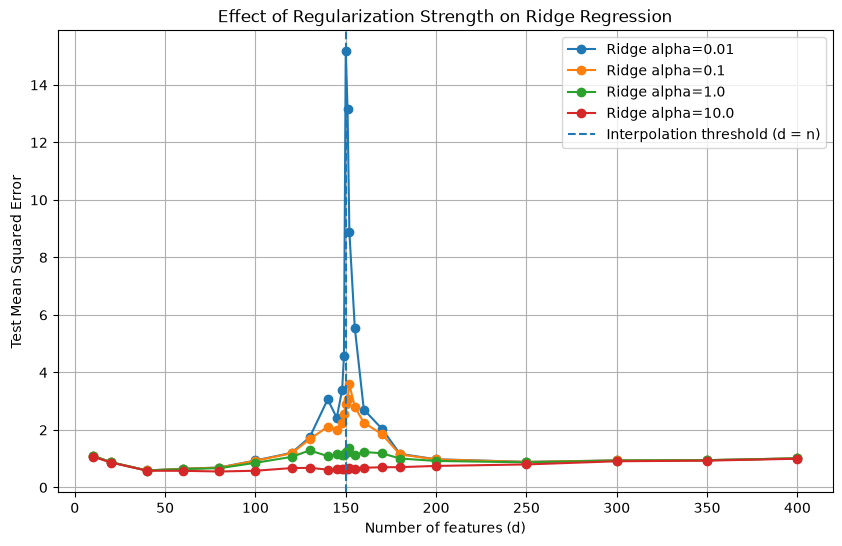

In [23]:
plt.figure(figsize=(10, 6))

for alpha in RIDGE_ALPHAS:
    plt.plot(
        D_VALUES,
        ridge_results[alpha],
        marker="o",
        label=f"Ridge alpha={alpha}"
    )

plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test Mean Squared Error")
plt.title("Effect of Regularization Strength on Ridge Regression")

plt.legend()
plt.grid(True)

plt.show()